# Лабораторная работа по Matplotlib

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Path('results').mkdir(exist_ok=True)

## Эпизод 1. Точки

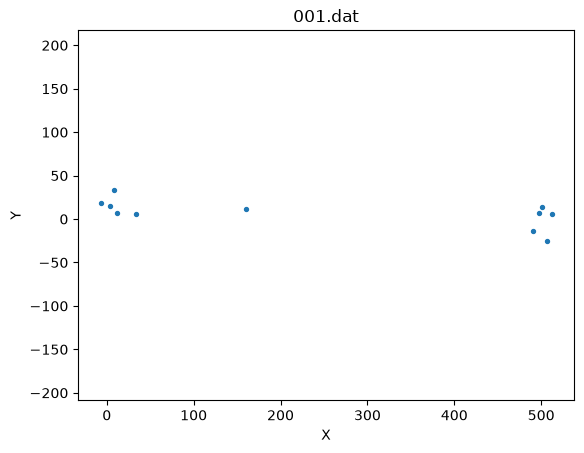

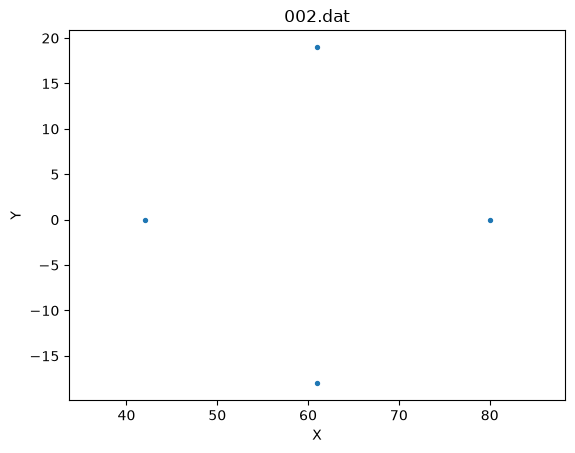

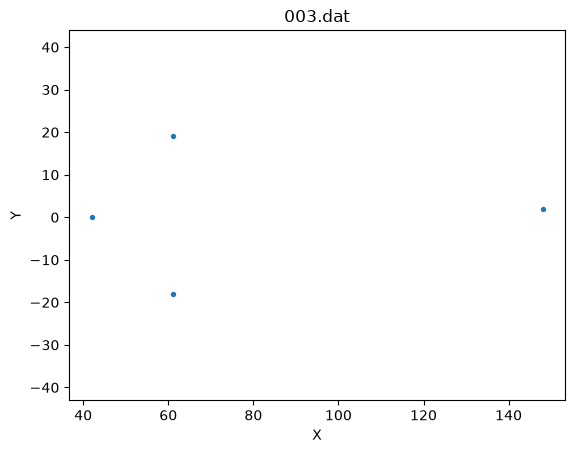

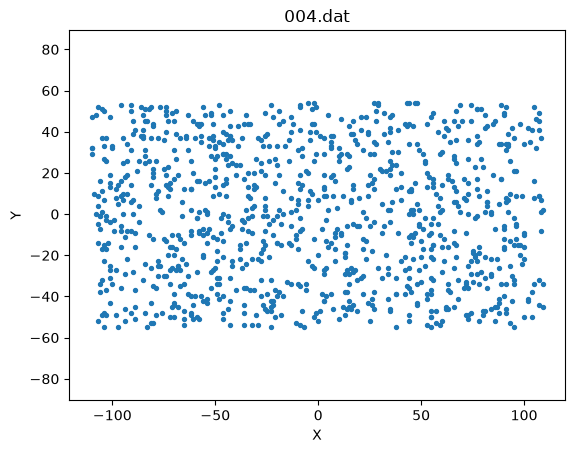

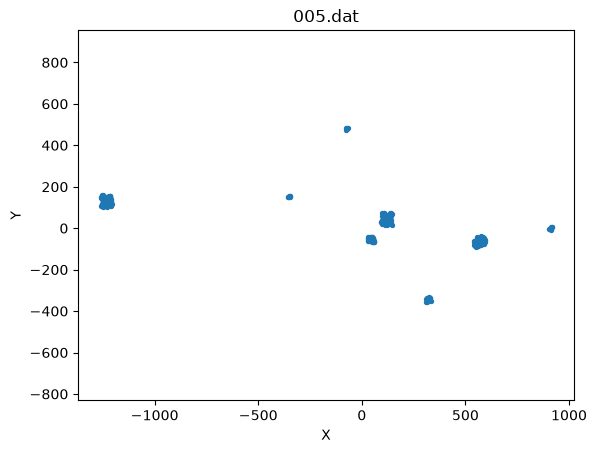

In [11]:
for file in sorted(Path('dead_moroz').rglob('*')):
    if file.is_file():
        with open(file, encoding='utf-8-sig') as f:
            n = int(f.readline())
            points = np.array([list(map(float, f.readline().split()[:2])) for _ in range(n)])

        plt.figure()
        plt.scatter(points[:, 0], points[:, 1], s=8)
        plt.axis('equal')
        plt.title(f'Набор: {file.stem}')
        plt.xlabel('Координата X')
        plt.ylabel('Координата Y')
        plt.show()

## Эпизод 2. Анимация

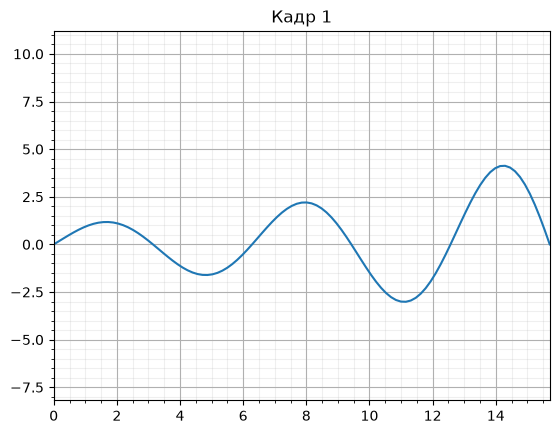

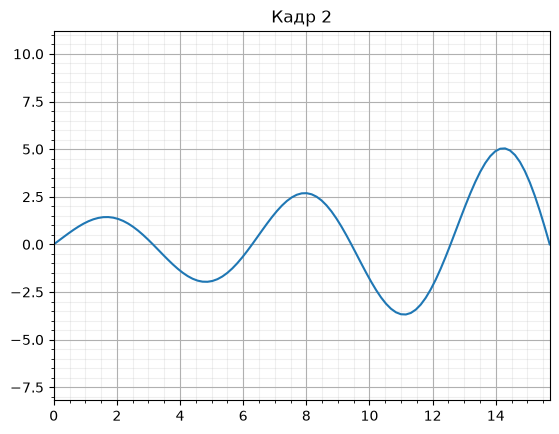

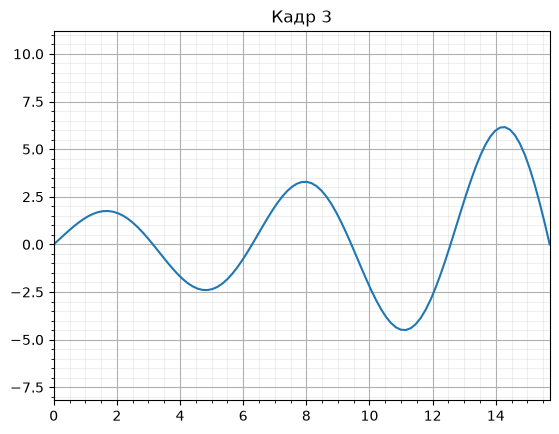

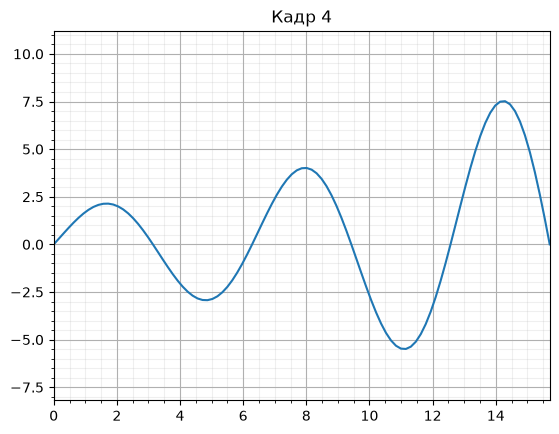

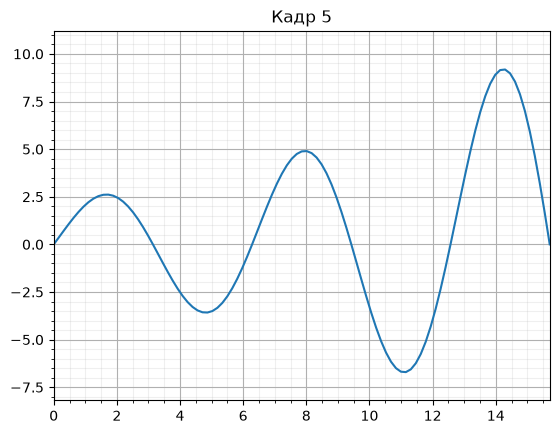

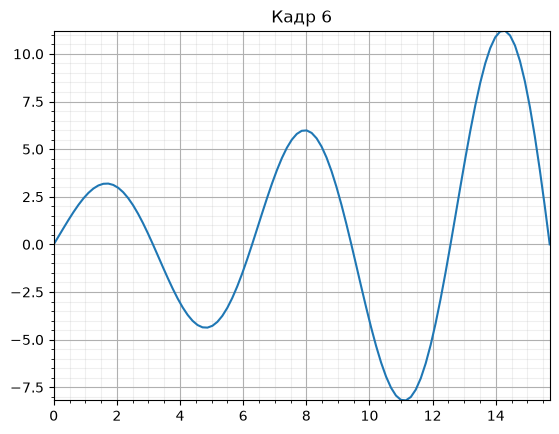

In [8]:
with open('frames.dat') as f:
    rows = [np.fromstring(line, sep=' ') for line in f if line.strip()]

frames = [(rows[i], rows[i + 1]) for i in range(0, len(rows), 2)]
xmin = min(x.min() for x, y in frames)
xmax = max(x.max() for x, y in frames)
ymin = min(y.min() for x, y in frames)
ymax = max(y.max() for x, y in frames)

for i, (x, y) in enumerate(frames, 1):
    plt.figure()
    plt.plot(x, y)
    plt.title(f'Кадр № {i}')
    plt.xlim(xmin, xmax)
    plt.ylim(ymin, ymax)
    plt.minorticks_on()
    plt.grid(which='major')
    plt.grid(which='minor', alpha=0.2)
    plt.show()

## Эпизод 3. Оценки

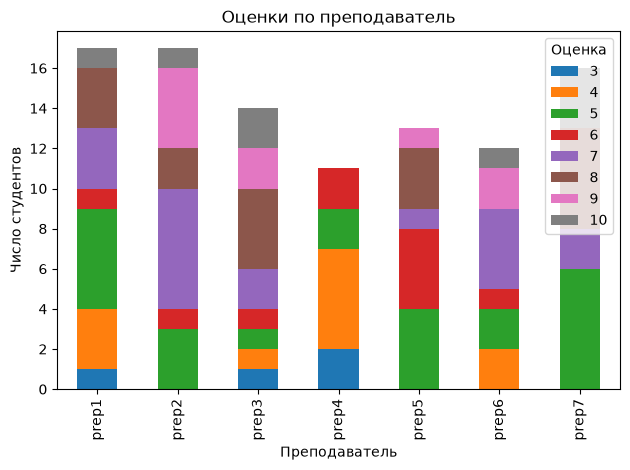

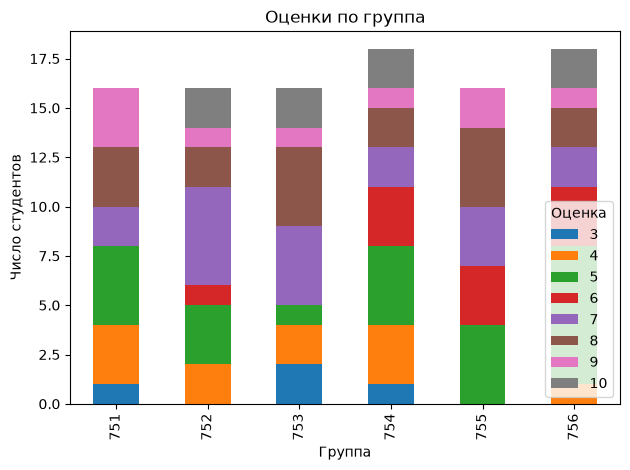

In [12]:
data = pd.read_csv('students.csv', sep=';', header=None,
                   names=['Преподаватель', 'Группа', 'Оценка'])

for column in ['Преподаватель', 'Группа']:
    pd.crosstab(data[column], data['Оценка']).plot.bar(stacked=True)
    plt.title(f'Распределение оценок: {column.lower().replace("преподаватель", "преподователь")}')
    plt.ylabel('Количество студентов')
    plt.tight_layout()
    plt.show()